## **6CS012 Artificial Intelligence and Machine Learning - Language Task**

### **Sarcasm Detection in News Headlines Using RNN, LSTM, and Word2Vec Embeddings**

**Name:** Luniva Shrestha  
**Student Number:** 2433240  
**Group Name:** L6CG23  
**Tutor:** Bijaya Ghimire  
**Module Leader:** Siman Giri

### **Introduction:**
This study focuses on detecting sarcasm in news headlines using deep learning models. The text data is preprocessed and converted into sequences for model training. Simple RNN, LSTM, and LSTM with pretrained Word2Vec embeddings are implemented and evaluated to compare their performance in sarcasm classification.

### **Dataset Description:**
sarcastic_headlines.csv

### **Source:**
https://drive.google.com/drive/folders/1DcQ4ekAW7FtOIU3ZnJk0CVqPWYQaFuaE

### **1: Importing necessary Libraries**

In [30]:
# Google Drive access
from google.colab import drive

# Install required libraries
!pip install pandas numpy matplotlib seaborn wordcloud nltk gensim tensorflow scikit-learn contractions gradio -q

# Core libraries
import pandas as pd
import numpy as np
import re
import time
import warnings

# Text processing utilities
import nltk
import contractions
import pickle

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Data handling
from collections import Counter
from nltk.stem import WordNetLemmatizer

# Deep learning (NLP models)
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Embedding, SimpleRNN, LSTM, Bidirectional,
    Dense, Dropout, SpatialDropout1D, Input
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Machine learning evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Word embeddings
import gensim.downloader as api

# Download NLTK resources
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

# Suppress warnings
warnings.filterwarnings("ignore")

# Confirmation
print("All necessary libraries imported successfully")

All necessary libraries imported successfully


### **2: Mount Drive**

In [31]:
# Mount Google Drive
drive.mount('/content/drive')

# Dataset path
data_path = '/content/drive/MyDrive/6CS012_AI/Sarcastic_or_Not_Sarcastic/sarcastic_headlines.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **3: Initial Analysis**

#### **3.1: Load Dataset**

In [32]:
# Load dataset
df = pd.read_csv(data_path)

# Show first rows
df.head()

,headline,is_sarcastic
0,thirtysomething scientists unveil doomsday clo...,1
1,dem rep. totally nails why congress is falling...,0
2,eat your veggies: 9 deliciously different recipes,0
3,inclement weather prevents liar from getting t...,1
4,mother comes pretty close to using word 'strea...,1


#### **3.2: Print Dataset Information**

In [33]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Column names
print("Columns:", df.columns.tolist())

# Label distribution
print("\nLabel Distribution:")
display(df['is_sarcastic'].value_counts())

Dataset Shape: (28619, 2)
Columns: ['headline', 'is_sarcastic']

Label Distribution:


,count
is_sarcastic,
0,14985
1,13634


#### **3.3: Class Distribution**

Class imbalance ratio (Not Sarcastic:Sarcastic): 1.0990905090215637


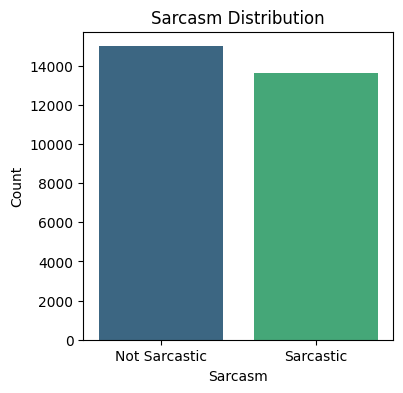

In [34]:
# Class distribution count
target_counts = Counter(df['is_sarcastic'])

# Imbalance ratio
if 0 in target_counts and 1 in target_counts and target_counts[1] != 0:
    print("Class imbalance ratio (Not Sarcastic:Sarcastic):", target_counts[0] / target_counts[1])
else:
    print("Class imbalance ratio (Not Sarcastic:Sarcastic): Cannot be calculated, one or both classes are missing or sarcastic count is zero.")

# Plot distribution
plt.figure(figsize=(4, 4))
sns.barplot(x=list(target_counts.keys()), y=list(target_counts.values()), palette='viridis')

plt.xlabel('Sarcasm')
plt.ylabel('Count')
plt.title('Sarcasm Distribution')
plt.xticks([0, 1], ['Not Sarcastic', 'Sarcastic'])

plt.show()

### **4: Data Cleaning**

In [35]:
# Lemmatizer and stopwords
lemmatizer = WordNetLemmatizer()

# Text cleaning function
def clean_text(text):
    if not isinstance(text, str):
        return ""

    # Expand contractions
    text = contractions.fix(text)

    # Lowercase text
    text = text.lower()

    # Remove URLs, mentions, hashtags
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)

    # Keep only letters
    text = re.sub(r'[^a-z\s]', '', text)

    # Tokenize + lemmatize
    words = text.split()
    words = [lemmatizer.lemmatize(word) for word in words if len(word) > 1]

    return " ".join(words)

### **5: Visualize Cleaned Data**

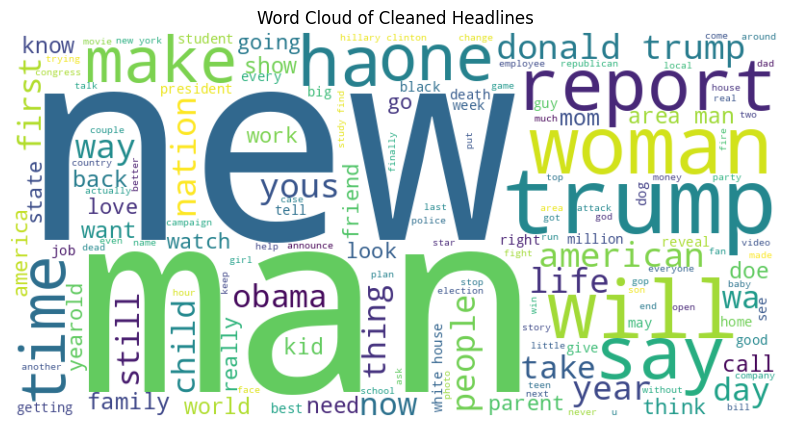

In [36]:
# Clean headlines
df['cleaned_headline'] = df['headline'].apply(clean_text)

# Word cloud of cleaned text
plt.figure(figsize=(10, 5))

all_text = " ".join(df['cleaned_headline'])
wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=150).generate(all_text)

plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Cleaned Headlines')

plt.show()

### **6: Tokenization and Padding**

#### **6.1: Train-Test Split**

In [37]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(df['cleaned_headline'], df['is_sarcastic'], test_size=0.2, random_state=42)

# Dataset sizes
print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

Training set size: 22895 samples
Testing set size: 5724 samples


#### **6.2: Text Tokenization with Keras**

In [38]:
# Tokenizer setup
tokenizer = Tokenizer(num_words=20000, oov_token="<oov>")
tokenizer.fit_on_texts(X_train)

# Convert text to sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_test_sequences  = tokenizer.texts_to_sequences(X_test)

# Vocabulary info
word_index    = tokenizer.word_index
vocab_size    = min(len(word_index) + 1, 20000)
embedding_dim = 128

# Print details
print(f"Vocabulary size : {vocab_size}")
print(f"Embedding dim   : {embedding_dim}")
print()
print("Sample original headline (cleaned):", X_train.iloc[0])
print("Sample sequence:", X_train_sequences[0][:10])

Vocabulary size : 20000
Embedding dim   : 128

Sample original headline (cleaned): how trump really feel about queer people explained in one sentence
Sample sequence: [30, 11, 125, 272, 19, 709, 65, 4279, 5, 47]


#### **6.3: Choosing Optimal Sequence

In [39]:
# Sequence length analysis
sequence_lengths = [len(x) for x in X_train_sequences]

# Choose max length (100th percentile)
max_len = int(np.percentile(sequence_lengths, 99))

# Print stats
print(f"Original max sequence length: {max(sequence_lengths)}")
print(f"Chosen max sequence length (99th percentile): {max_len}")

Original max sequence length: 37
Chosen max sequence length (99th percentile): 18


#### **6.4: Distribution of Sequence Length

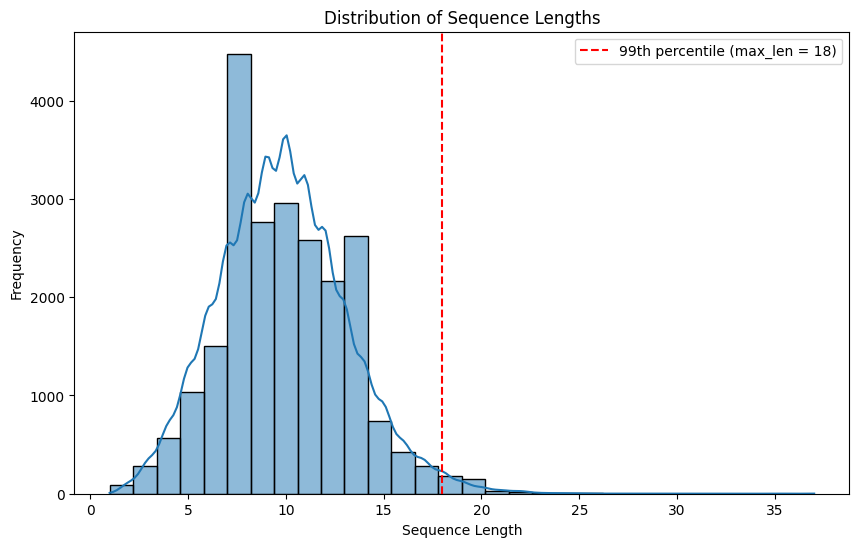

In [40]:
plt.figure(figsize=(10, 6))
sns.histplot(sequence_lengths, bins=30, kde=True)
plt.axvline(x=max_len, color='r', linestyle='--', label=f'99th percentile (max_len = {max_len})')
plt.title('Distribution of Sequence Lengths')
plt.xlabel('Sequence Length')
plt.ylabel('Frequency')
plt.legend()
plt.show()

#### **6.5: Padding Sequences to Uniform Length Using Keras**

In [41]:
# Pad sequences
X_train_padded = pad_sequences(X_train_sequences, maxlen=max_len, padding='post', truncating='post')
X_test_padded = pad_sequences(X_test_sequences, maxlen=max_len, padding='post', truncating='post')

# Shapes
print("\nShape of X_train_padded:", X_train_padded.shape)
print("Shape of X_test_padded:", X_test_padded.shape)

# Sample output
print("Sample padded sequence (first 10 elements):", X_train_padded[0][:10])


Shape of X_train_padded: (22895, 18)
Shape of X_test_padded: (5724, 18)
Sample padded sequence (first 10 elements): [  30   11  125  272   19  709   65 4279    5   47]


### **7: Model Development**

#### **7.1: Simple RNN**

##### **7.1.1: Build Simple RNN Model**

In [42]:
# Simple RNN model
model_rnn = Sequential([
    Input(shape=(max_len,)),
    Embedding(input_dim=vocab_size, output_dim=128),
    SpatialDropout1D(0.3),
    SimpleRNN(64, dropout=0.3, return_sequences=False),
    Dense(1, activation="sigmoid")
])

# Compile model
model_rnn.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# Model summary
model_rnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 18, 128)        │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_3             │ (None, 18, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,572,417 (9.81 MB)

 Trainable params: 2,572,417 (9.81 MB)

 Non-trainable params: 0 (0.00 B)

##### **7.1.2: Train Simple RNN Model**

In [43]:
# Callbacks
ear_stop_rnn  = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)
reduce_lr_rnn = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)

checkpoint_rnn = ModelCheckpoint("best_rnn_model.keras", monitor="val_loss", save_best_only=True, verbose=1)
callbacks_rnn = [ear_stop_rnn, reduce_lr_rnn, checkpoint_rnn]

# Train RNN model
print("Training Simple RNN Model.. \n")
start_time_rnn = time.time()

history_rnn = model_rnn.fit(
    X_train_padded, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks_rnn,
    verbose=1
)

# Training time
end_time_rnn = time.time()
training_time_rnn = end_time_rnn - start_time_rnn

print(f"Simple RNN Training Time: {training_time_rnn:.2f} seconds")

Training Simple RNN Model.. 

Epoch 1/15
287/287 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6974 - loss: 0.5460
Epoch 1: val_loss improved from None to 0.40742, saving model to best_rnn_model.keras

Epoch 1: finished saving model to best_rnn_model.keras
287/287 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.7750 - loss: 0.4593 - val_accuracy: 0.8231 - val_loss: 0.4074 - learning_rate: 0.0010
Epoch 2/15
285/287 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9107 - loss: 0.2307
Epoch 2: val_loss did not improve from 0.40742
287/287 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9087 - loss: 0.2310 - val_accuracy: 0.8342 - val_loss: 0.4799 - learning_rate: 0.0010
Epoch 3/15
280/287 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9634 - loss: 0.1038
Epoch 3: val_loss did not improve from 0.40742
287/287 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9609 - loss: 0.1086 - val_accuracy: 0.8303 - val_loss: 0.4626 - learning_rate: 0.0010
Epoch 4/15
284/287 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/ste

##### **7.1.3: Plot Simple RNN Model Curves**

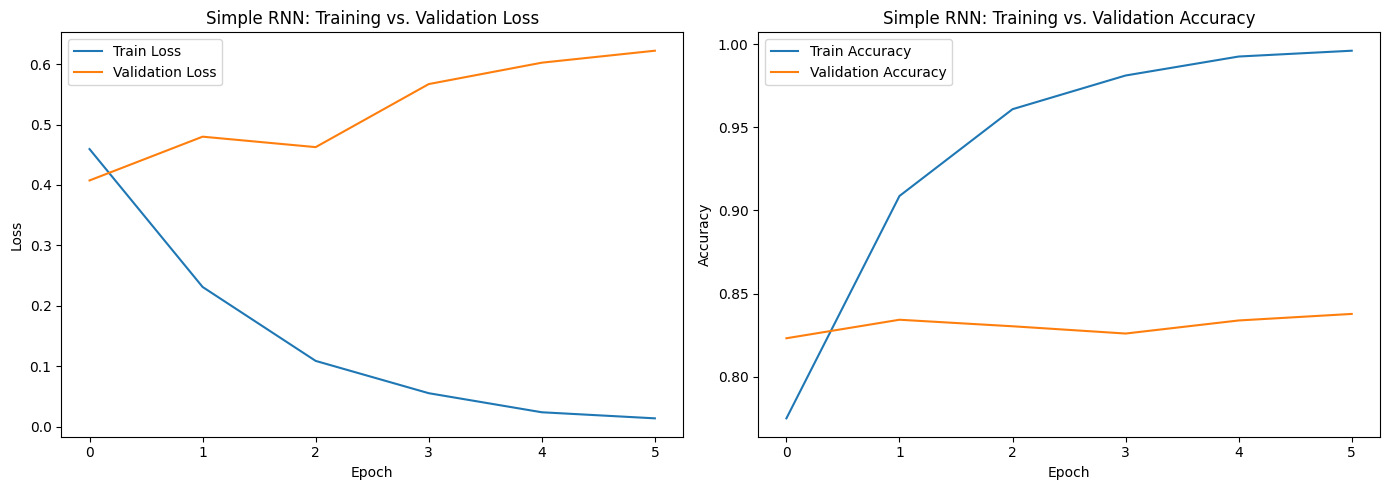

In [44]:
# Plot training performance (RNN)
plt.figure(figsize=(14, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(history_rnn.history['loss'], label='Train Loss')
plt.plot(history_rnn.history['val_loss'], label='Validation Loss')
plt.title('Simple RNN: Training vs. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(history_rnn.history['accuracy'], label='Train Accuracy')
plt.plot(history_rnn.history['val_accuracy'], label='Validation Accuracy')
plt.title('Simple RNN: Training vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

##### **7.1.4: Evaluate Simple RNN Model**

In [45]:
# Evaluate RNN model
loss_rnn, accuracy_rnn = model_rnn.evaluate(X_test_padded, y_test, verbose=0)

print(f"Simple RNN Test Loss: {loss_rnn:.4f}")
print(f"Simple RNN Test Accuracy: {accuracy_rnn:.4f}")

# Convert Predictions into Class Labels
y_pred_rnn = (model_rnn.predict(X_test_padded) > 0.5).astype("int32")

# Classification report
print("\nSimple RNN Classification Report:")
print(classification_report(y_test, y_pred_rnn))

Simple RNN Test Loss: 0.4211
Simple RNN Test Accuracy: 0.8213
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

Simple RNN Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.72      0.81      2995
           1       0.75      0.93      0.83      2729

    accuracy                           0.82      5724
   macro avg       0.84      0.83      0.82      5724
weighted avg       0.84      0.82      0.82      5724



##### **7.1.5: Simple RNN Confusion Matrix**

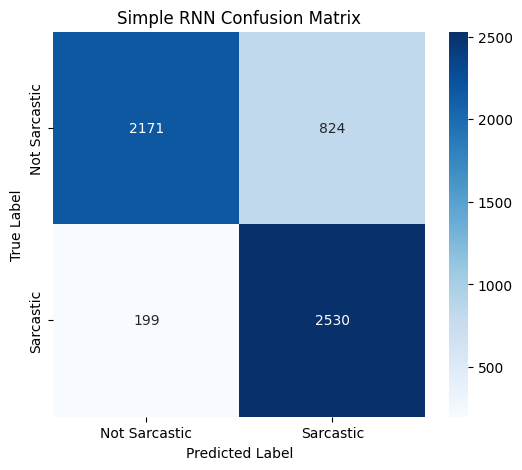

In [46]:
# Confusion matrix for RNN
cm_rnn = confusion_matrix(y_test, y_pred_rnn)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_rnn, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Sarcastic', 'Sarcastic'],
            yticklabels=['Not Sarcastic', 'Sarcastic'])

plt.title('Simple RNN Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

#### **7.2: LSTM with Trainable Embedding**

##### **7.2.1: Build LSTM Model**

In [47]:
# Bidirectional LSTM model
model_lstm = Sequential([
    Input(shape=(max_len,)),
    Embedding(input_dim=vocab_size, output_dim=128),
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(64, dropout=0.3, return_sequences=False)),
    Dense(1, activation="sigmoid")
])

# Compile model
model_lstm.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# Model summary
model_lstm.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 18, 128)        │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_4             │ (None, 18, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,658,945 (10.14 MB)

 Trainable params: 2,658,945 (10.14 MB)

 Non-trainable params: 0 (0.00 B)

##### **7.2.2: Train LSTM Model**

In [48]:
# Callbacks for LSTM
ear_stop_lstm  = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)
reduce_lr_lstm = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)

checkpoint_lstm = ModelCheckpoint("best_lstm_model.keras", monitor="val_loss", save_best_only=True, verbose=1)
callbacks_lstm = [ear_stop_lstm, reduce_lr_lstm, checkpoint_lstm]

# Train LSTM model
print("Training LSTM Model.. \n")
start_time_lstm = time.time()

history_lstm = model_lstm.fit(
    X_train_padded, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks_lstm,
    verbose=1
)

# Training time
end_time_lstm = time.time()
training_time_lstm = end_time_lstm - start_time_lstm

print(f"LSTM Training Time: {training_time_lstm:.2f} seconds")

Training LSTM Model.. 

Epoch 1/15
282/287 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6844 - loss: 0.5490
Epoch 1: val_loss improved from None to 0.35450, saving model to best_lstm_model.keras

Epoch 1: finished saving model to best_lstm_model.keras
287/287 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.7748 - loss: 0.4449 - val_accuracy: 0.8471 - val_loss: 0.3545 - learning_rate: 0.0010
Epoch 2/15
284/287 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9121 - loss: 0.2259
Epoch 2: val_loss improved from 0.35450 to 0.35448, saving model to best_lstm_model.keras

Epoch 2: finished saving model to best_lstm_model.keras
287/287 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9064 - loss: 0.2329 - val_accuracy: 0.8445 - val_loss: 0.3545 - learning_rate: 0.0010
Epoch 3/15
285/287 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9530 - loss: 0.1344
Epoch 3: val_loss did not improve from 0.35448
287/287 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9494 - loss: 0.1399 - val_accuracy: 0.8

##### **7.2.3: Plot LSTM Model Curves**

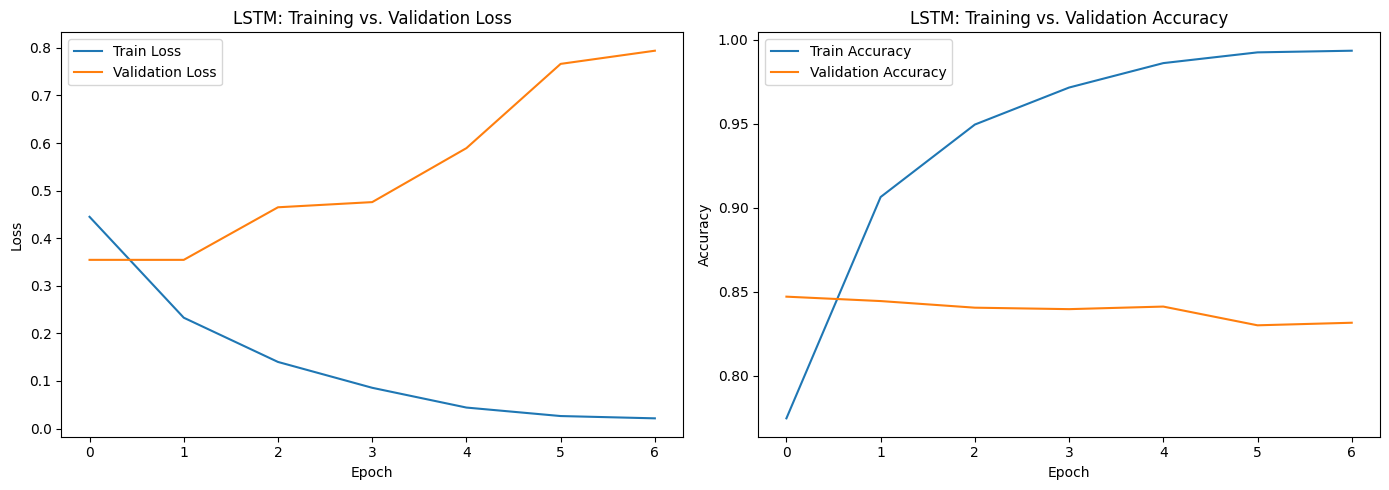

In [49]:
# Plot LSTM training vs validation performance
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_lstm.history['loss'], label='Train Loss')
plt.plot(history_lstm.history['val_loss'], label='Validation Loss')
plt.title('LSTM: Training vs. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_lstm.history['accuracy'], label='Train Accuracy')
plt.plot(history_lstm.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM: Training vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

##### **7.2.4: Evaluate LSTM Model**

In [50]:
# Evaluate LSTM model on test data
loss_lstm, accuracy_lstm = model_lstm.evaluate(X_test_padded, y_test, verbose=0)

print(f"LSTM Test Loss: {loss_lstm:.4f}")
print(f"LSTM Test Accuracy: {accuracy_lstm:.4f}")

# Predictions
y_pred_lstm = (model_lstm.predict(X_test_padded) > 0.5).astype("int32")

# Classification report
print("\nLSTM Classification Report:")
print(classification_report(y_test, y_pred_lstm))

LSTM Test Loss: 0.3450
LSTM Test Accuracy: 0.8457
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

LSTM Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      2995
           1       0.86      0.81      0.83      2729

    accuracy                           0.85      5724
   macro avg       0.85      0.84      0.84      5724
weighted avg       0.85      0.85      0.85      5724



##### **7.2.5: LSTM Confusion Matrix**

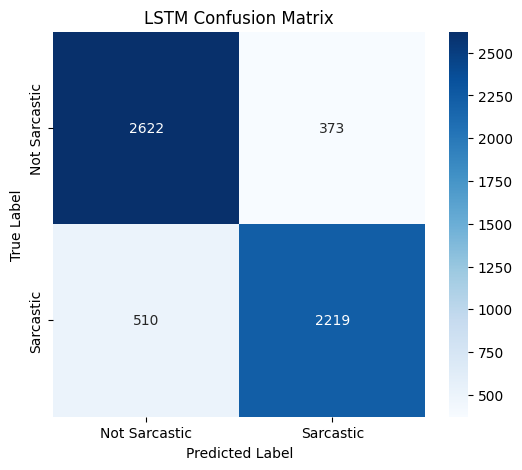

In [51]:
# Confusion matrix for LSTM model
cm_lstm = confusion_matrix(y_test, y_pred_lstm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_lstm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Sarcastic', 'Sarcastic'],
            yticklabels=['Not Sarcastic', 'Sarcastic'])

plt.title('LSTM Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

#### **7.3: LSTM with Pre-trained Word2Vec Embeddings**

##### **7.3.1: Loading LSTM with Word2Vec Model**

In [52]:
# Load pre-trained Word2Vec model
print("Loading Word2Vec model...")
word2vec_model = api.load("word2vec-google-news-300")
print("Word2Vec model loaded!")

# Create embedding matrix using Word2Vec
embedding_matrix_w2v = np.zeros((vocab_size, 300))
hit, miss = 0, 0

for word, idx in word_index.items():
    if idx < vocab_size:
        if word in word2vec_model:
            embedding_matrix_w2v[idx] = word2vec_model[word]
            hit += 1
        else:
            embedding_matrix_w2v[idx] = np.random.normal(scale=0.6, size=(300,))
            miss += 1

# Summary stats
print(f"Words found in Word2Vec : {hit}")
print(f"Words missing           : {miss}")
print(f"Embedding matrix shape  : {embedding_matrix_w2v.shape}")

Loading Word2Vec model...
Word2Vec model loaded!
Words found in Word2Vec : 16272
Words missing           : 3727
Embedding matrix shape  : (20000, 300)


##### **7.3.2: Build LSTM with Word2Vec Model**

In [53]:
# LSTM model with Word2Vec embeddings
model_lstm_w2v = Sequential([
    Input(shape=(max_len,)),
    Embedding(input_dim=vocab_size, output_dim=300,
              weights=[embedding_matrix_w2v], trainable=True),
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(64, dropout=0.3, return_sequences=False)),
    Dense(1, activation="sigmoid")
])

# Compile model
model_lstm_w2v.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# Model summary
model_lstm_w2v.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 18, 300)        │     6,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_5             │ (None, 18, 300)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 128)            │       186,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,187,009 (23.60 MB)

 Trainable params: 6,187,009 (23.60 MB)

 Non-trainable params: 0 (0.00 B)

##### **7.3.3: Train LSTM with Word2Vec Model**

In [54]:
# Callbacks for LSTM with Word2Vec
ear_stop_w2v  = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1)
reduce_lr_w2v = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1)

checkpoint_lstm_w2v = ModelCheckpoint("best_lstm_w2v_model.keras", monitor="val_loss", save_best_only=True, verbose=1)
callbacks_lstm_w2v = [ear_stop_w2v, reduce_lr_w2v, checkpoint_lstm_w2v]

# Train model
print("Training LSTM with Word2Vec Model.. \n")
start_time_lstm_w2v = time.time()

history_lstm_w2v = model_lstm_w2v.fit(
    X_train_padded, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks_lstm_w2v,
    verbose=1
)

# Training time
end_time_lstm_w2v = time.time()
training_time_lstm_w2v = end_time_lstm_w2v - start_time_lstm_w2v

print(f"LSTM with Word2Vec Training Time: {training_time_lstm_w2v:.2f} seconds")

Training LSTM with Word2Vec Model.. 

Epoch 1/15
284/287 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7194 - loss: 0.5309
Epoch 1: val_loss improved from None to 0.34654, saving model to best_lstm_w2v_model.keras

Epoch 1: finished saving model to best_lstm_w2v_model.keras
287/287 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.7833 - loss: 0.4464 - val_accuracy: 0.8504 - val_loss: 0.3465 - learning_rate: 0.0010
Epoch 2/15
286/287 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8881 - loss: 0.2718
Epoch 2: val_loss improved from 0.34654 to 0.31620, saving model to best_lstm_w2v_model.keras

Epoch 2: finished saving model to best_lstm_w2v_model.keras
287/287 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8876 - loss: 0.2713 - val_accuracy: 0.8635 - val_loss: 0.3162 - learning_rate: 0.0010
Epoch 3/15
284/287 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9301 - loss: 0.1854
Epoch 3: val_loss did not improve from 0.31620
287/287 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9265 - 

##### **7.3.4: Train LSTM with Word2Vec Model**

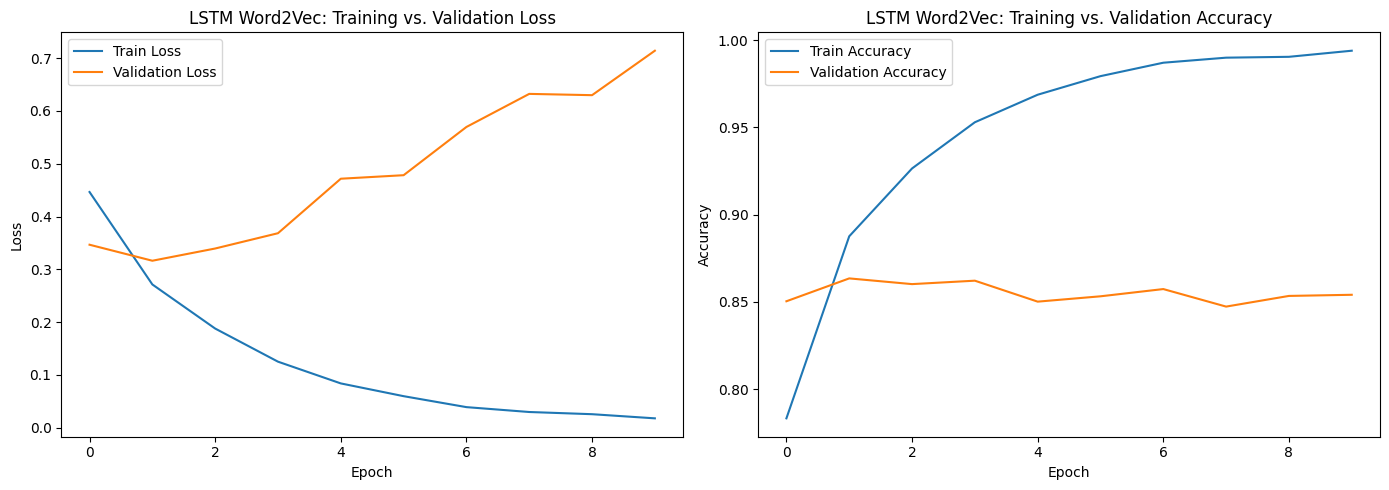

In [55]:
# Plot LSTM with Word2Vec training performance
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_lstm_w2v.history['loss'], label='Train Loss')
plt.plot(history_lstm_w2v.history['val_loss'], label='Validation Loss')
plt.title('LSTM Word2Vec: Training vs. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_lstm_w2v.history['accuracy'], label='Train Accuracy')
plt.plot(history_lstm_w2v.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Word2Vec: Training vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

##### **7.3.5: Evaluate LSTM with Word2Vec Model**

In [56]:
# Evaluate LSTM with Word2Vec
loss_lstm_w2v, accuracy_lstm_w2v = model_lstm_w2v.evaluate(X_test_padded, y_test, verbose=0)

print(f"LSTM with Word2Vec Test Loss: {loss_lstm_w2v:.4f}")
print(f"LSTM with Word2Vec Test Accuracy: {accuracy_lstm_w2v:.4f}")

# Predictions
y_pred_lstm_w2v = (model_lstm_w2v.predict(X_test_padded) > 0.5).astype("int32")

# Classification report
print("\nLSTM with Word2Vec Classification Report:")
print(classification_report(y_test, y_pred_lstm_w2v))

LSTM with Word2Vec Test Loss: 0.3109
LSTM with Word2Vec Test Accuracy: 0.8599
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

LSTM with Word2Vec Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.85      0.86      2995
           1       0.84      0.87      0.85      2729

    accuracy                           0.86      5724
   macro avg       0.86      0.86      0.86      5724
weighted avg       0.86      0.86      0.86      5724



##### **7.3.6: LSTM with Word2Vec Confusion Matrix**

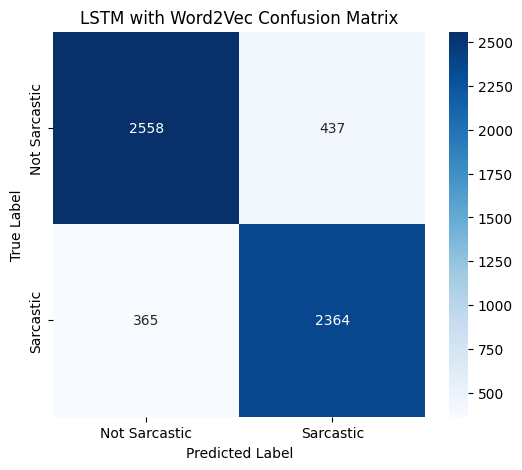

In [57]:
# Confusion matrix for LSTM with Word2Vec
cm_lstm_w2v = confusion_matrix(y_test, y_pred_lstm_w2v)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_lstm_w2v, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Sarcastic', 'Sarcastic'],
            yticklabels=['Not Sarcastic', 'Sarcastic'])

plt.title('LSTM with Word2Vec Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

### **8: Model Comparison**

#### **8.1: Model Comparison Table**

In [58]:
# Precision, Recall, F1 for RNN
precision_rnn = precision_score(y_test, y_pred_rnn, average='weighted')
recall_rnn = recall_score(y_test, y_pred_rnn, average='weighted')
f1_rnn = f1_score(y_test, y_pred_rnn, average='weighted')

# Precision, Recall, F1 for LSTM
precision_lstm = precision_score(y_test, y_pred_lstm, average='weighted')
recall_lstm = recall_score(y_test, y_pred_lstm, average='weighted')
f1_lstm = f1_score(y_test, y_pred_lstm, average='weighted')

# Precision, Recall, F1 for LSTM with Word2Vec
precision_lstm_w2v = precision_score(y_test, y_pred_lstm_w2v, average='weighted')
recall_lstm_w2v = recall_score(y_test, y_pred_lstm_w2v, average='weighted')
f1_lstm_w2v = f1_score(y_test, y_pred_lstm_w2v, average='weighted')

# Model comparison table
model_comparison_df = pd.DataFrame({
    "Model": ["Simple RNN", "LSTM", "LSTM with Word2Vec"],
    "Accuracy": [accuracy_rnn, accuracy_lstm, accuracy_lstm_w2v],
    "Precision": [precision_rnn, precision_lstm, precision_lstm_w2v],
    "Recall": [recall_rnn, recall_lstm, recall_lstm_w2v],
    "F1-Score": [f1_rnn, f1_lstm, f1_lstm_w2v],
    "Training Time (s)": [training_time_rnn, training_time_lstm, training_time_lstm_w2v]
})

# Display results
print("Model Performance Comparison\n")
display(model_comparison_df)

Model Performance Comparison



,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s)
0,Simple RNN,0.821279,0.838936,0.821279,0.820050,24.182981
1,LSTM,0.845737,0.846190,0.845737,0.845476,25.640845
2,LSTM with Word2Vec,0.859888,0.860280,0.859888,0.859948,43.865013


#### **8.2: Model Comparison Plot**

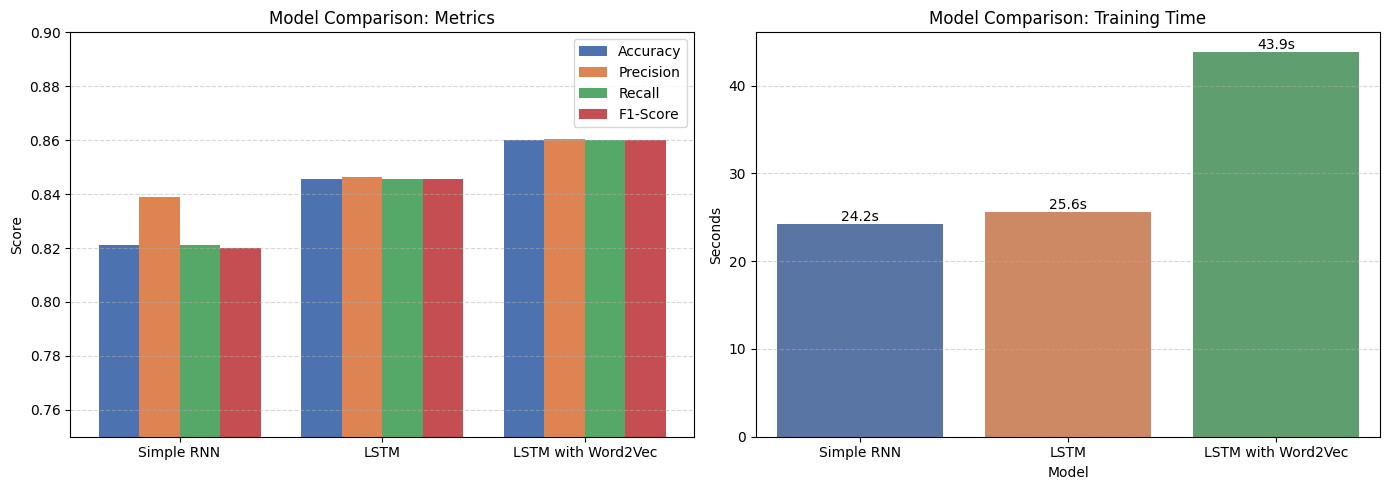

In [59]:
# Model names and positions
models = model_comparison_df['Model']
x = np.arange(len(models))
width = 0.2

# Set seaborn style
sns.set_palette("deep")

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Metrics comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

for i, metric in enumerate(metrics):
    axes[0].bar(x + i * width, model_comparison_df[metric], width, label=metric)

axes[0].set_xticks(x + width * 1.5)
axes[0].set_xticklabels(models)
axes[0].set_ylim(0.75, 0.90)
axes[0].set_ylabel('Score')
axes[0].set_title('Model Comparison: Metrics')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Training time comparison
sns.barplot(x=models, y=model_comparison_df['Training Time (s)'], ax=axes[1], palette="deep")

axes[1].set_title('Model Comparison: Training Time')
axes[1].set_ylabel('Seconds')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# Add value labels
for i, v in enumerate(model_comparison_df['Training Time (s)']):
    axes[1].text(i, v, f'{v:.1f}s', ha='center', va='bottom')

plt.tight_layout()
plt.show()

#### **8.3: Deeper Insight into Model Differences**

*   **Simple RNN:** Limited by short-term memory, struggles with long dependencies.
*   **LSTM:** Excels at capturing longer dependencies using gating mechanisms, outperforming RNNs.
*   **LSTM with Pre-trained Word2Vec:** Combines LSTM's sequence understanding with rich, external semantic knowledge from Word2Vec, allowing it to better discern subtle sarcasm by understanding word relationships and contexts. This combination yields the best performance.

#### **8.4: Hyperparameter Tuning**



Optimizing hyperparameters like embedding dimension, LSTM unit count, and dropout rates is crucial. While early stopping and learning rate reduction are used, systematic tuning (e.g., Grid Search, Random Search, Bayesian Optimization) could further enhance model accuracy and efficiency by finding optimal configurations.

### **9: Error Analysis**

#### **9.1: Analyze Misclassified Examples (Using LSTM with Word2Vec Model)**

In [60]:
# Convert test labels and predictions to lists
y_test_list = y_test.tolist()
y_pred_lstm_w2v_list = y_pred_lstm_w2v.flatten().tolist()

# Find misclassified indices
misclassified_indices = [
    i for i, (true, pred) in enumerate(zip(y_test_list, y_pred_lstm_w2v_list))
    if true != pred
]

# Summary
print(f"Total misclassified examples by LSTM with Word2Vec: {len(misclassified_indices)}\n")

num_examples_to_show = 5
print(f"Showing {min(num_examples_to_show, len(misclassified_indices))} misclassified examples:")

# Display misclassified samples
for i, idx in enumerate(misclassified_indices[:num_examples_to_show]):
    original_headline = df['headline'].iloc[X_test.index[idx]]
    cleaned_headline = X_test.iloc[idx]
    true_label = y_test_list[idx]
    predicted_label = y_pred_lstm_w2v_list[idx]

    print(f"\nMisclassified Example {i+1}\n")
    print(f"Original Headline: {original_headline}")
    print(f"Cleaned Headline: {cleaned_headline}")
    print(f"True Label: {'Sarcastic' if true_label == 1 else 'Not Sarcastic'}")
    print(f"Predicted Label: {'Sarcastic' if predicted_label == 1 else 'Not Sarcastic'}")

Total misclassified examples by LSTM with Word2Vec: 802

Showing 5 misclassified examples:

Misclassified Example 1

Original Headline: states slow to shut down weak teacher education programs
Cleaned Headline: state slow to shut down weak teacher education program
True Label: Not Sarcastic
Predicted Label: Sarcastic

Misclassified Example 2

Original Headline: massive filament snakes across sun's surface
Cleaned Headline: massive filament snake across sun surface
True Label: Not Sarcastic
Predicted Label: Sarcastic

Misclassified Example 3

Original Headline: robin hood foundation
Cleaned Headline: robin hood foundation
True Label: Not Sarcastic
Predicted Label: Sarcastic

Misclassified Example 4

Original Headline: dude with knit hat at party calls beer 'libations'
Cleaned Headline: dude with knit hat at party call beer libation
True Label: Sarcastic
Predicted Label: Not Sarcastic

Misclassified Example 5

Original Headline: sharper image vows 'we will be undersold'
Cleaned Headline:

#### **9.2: Discussion on Misclassified Examples**

Misclassified examples highlight core challenges:

*   **Sentiment vs. Sarcasm:** Models confuse strong negative sentiment (e.g., "states slow to shut down weak teacher education programs") with sarcastic critique.
*   **Subtle Irony/Absurdity:** Genuinely sarcastic headlines (e.g., "eighth-grader drinks at twelfth-grade level") are often missed due to the model's inability to detect inherent absurdity.
*   **Literal Interpretation:** Models can misinterpret vivid or metaphorical language (e.g., "massive filament snakes across sun's surface") as sarcastic, or struggle with short, neutral phrases (e.g., "robin hood foundation") lacking context.

This shows models struggle to differentiate true intent when faced with strong sentiment, subtle irony, or insufficient context.

#### **9.3: Model Complexity vs. Performance Evaluation**

Performance generally improved with increased model complexity:

*   **Simple RNN:** Fastest but lowest performance, limited in capturing complex patterns.
*   **LSTM with Trainable Embedding:** Better performance, benefiting from sequential data handling and learned word representations.
*   **LSTM with Pre-trained Word2Vec Embeddings:** Highest performance, leveraging external semantic knowledge for superior sarcasm detection, despite longer training times. This model offered the best balance for the task.

#### **9.4: Possible Reasons for Error**

Misclassifications stem from:

1.  **Subtlety of Sarcasm:** Irony and cultural context are hard for models to grasp, especially in short headlines.
2.  **Ambiguity:** Words used both literally and sarcastically confuse models.
3.  **Limited Context:** Brief headlines offer insufficient data for accurate intent discernment.
4.  **Data Issues:** Potential imbalances or underrepresentation of certain linguistic styles.
5.  **Word2Vec Limitations:** Static embeddings fail to capture polysemy or context-dependent meaning, crucial for sarcasm.

#### **9.5: Suggested Potential Improvements**

To boost performance, consider:

1.  **Advanced Embeddings:** Use contextualized models like BERT or RoBERTa.
2.  **More Data:** Larger, diverse datasets and data augmentation.
3.  **Ensemble Methods:** Combine predictions from multiple models.
4.  **Hyperparameter Tuning:** Optimize learning rates, dropout, etc.
5.  **Attention Mechanisms:** Focus on key sarcastic cues.
6.  **Feature Engineering:** Extract punctuation patterns, sentiment scores, and lexical features.
7.  **Alternative Architectures:** Explore CNNs or Transformer models.

### **10: Save Trained Model**

In [61]:
# Save trained LSTM model
model_lstm_w2v.save("sarcasm_model.h5")

# Save tokenizer
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Model and tokenizer saved successfully.")

Model and tokenizer saved successfully.


### **11: GUI for Real-Time Prediction (using Gradio)**

#### **11.1: Load Saved Model**

In [62]:
# Load saved model
model_lstm_w2v = load_model("sarcasm_model.h5")

# Load tokenizer
with open("tokenizer.pkl", "rb") as f:
    tokenizer = pickle.load(f)

print("Model and tokenizer loaded successfully.")

Model and tokenizer loaded successfully.


#### **11.2: Define Prediction Function**

In [63]:
# Prediction function for sarcasm detection
def predict_sarcasm(headline):
    cleaned_headline = clean_text(headline)

    sequence = tokenizer.texts_to_sequences([cleaned_headline])
    padded_sequence = pad_sequences(
        sequence,
        maxlen=max_len,
        padding='post',
        truncating='post'
    )

    prediction = model_lstm_w2v.predict(padded_sequence)[0][0]

    if prediction >= 0.5:
        return f"Sarcastic (Confidence: {prediction:.2f})"
    else:
        return f"Not Sarcastic (Confidence: {1 - prediction:.2f})"

# Confirmation
print("Prediction function defined")

Prediction function defined


#### **11.3: Create and Launch Gradio Interface**


In [64]:
# Gradio interface for sarcasm detection
import gradio as gr

iface = gr.Interface(
    # Run predict_sarcasm
    fn=predict_sarcasm,

    # Input textbox for headline
    inputs=gr.Textbox(
        lines=3, # Height of textbox
        placeholder="Enter a news headline here..."
    ),

    # Output prediction textbox
    outputs=gr.Textbox(label="Prediction"),

    title="Sarcasm Detector for News Headlines",

    description="Detect whether a given news headline is sarcastic using an LSTM model with Word2Vec embeddings.",

    theme=gr.themes.Soft(),

    allow_flagging="never"
)

# Launch app
iface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5c2062a165ae1aa571.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### **Conclusion**

This study effectively compared Simple RNN, LSTM, and LSTM with Word2Vec for sarcasm detection in news headlines. The LSTM model with pre-trained Word2Vec embeddings achieved the highest performance, demonstrating the value of semantic knowledge in complex NLP tasks, despite challenges in capturing subtle nuances of sarcasm.